# COURSEWORK SPECIFICATION

## COM1011 - Fundamentals of Machine Learning


**Title:** Coursework 2

_____________________

# Part A – Probability and Bayesian Inference [10 marks]

Consider a simple poker game. Suppose a deck of poker cards contains four suits: Clubs, Spades, Hearts, and Diamonds, with each suit having 8 cards numbered from 1 to 8. So the total number of cards is 32. The card with the number 8 is the largest, while the card with the number 1 is the smallest. Cards of different suits with the same number are considered equal.

**(1) Suppose person A fetches a card with the number 3 of Clubs from the deck. Person B then fetches another card from the deck. What is the probability that person B's card is less than person A's card? Explain how you arrived at the answer. [1 mark]**

Answer to (1): P(B card less than A's) = 8/31
Since person A picked a card there are 31 cards left. Cards that are less than 3 are 2 and 1. Multiplied across 4 suits that is 8 cards.

**(2) If you have drawn four cards sequentially from the deck of 32 cards. What is the total probability that the four cards have the same number 3? (1 mark)**



Answer to (2): P(Drawing the 3 card 4 times) = 1/35960

**(3) If you have drawn four cards sequentially from the deck of 32 cards. What is the total probability that the four cards are of Clubs? Explain how you arrived at the answer [1 mark]**


Answer to (2): P(4 clubs cards) = 7/3596
The number of ways to pick 4 clubs from 8 clubs is 70. The number of ways to pick 4 cards from 32 is 35960. So the final probability is the first one over the second one to create a fractional probability of picking 4 clubs over all possible combinations of 4 cards


**(4) Suppose person A fetches a card with the number 3 of Hearts from the deck. Person B then fetches another card with the number 6 from the deck. What is the probability that person B's card is also of Hearts? Explain how you arrived at the answer by using Bayesian formula. [2 mark]**

Answer to (4): P(6H|6) = 1/4
Using the Bayesian formula we first find the intersection of picking the 6 of hearts card and picking any 6 card. This probability is 1/31 since the 3 of hearts has already been picked. Then we find the probability that any 6 card is picked and that is 4/31. When we divide these two probabilities as shown in the Bayesian formula we get 1/4

**(5) Suppose person A fetches a card with the number 2 from the deck of 32 cards. Person B then fetches another card with the number 4 from the deck. What is the probability that person B's card and A's card have the same suit? Explain how you arrived at the answer by using Bayesian formula. [2 marks]**

Answer to (5): P(B same suit as A|4 was picked) = 1/4
We first find the probability of the intersection of a 4 being picked and the card being the same suit as the card picked by person A, which is 1/31, since a card has already been picked. Then we find the probability that a 4 card is picked and that is 4/31. Then we divide these two probabilities as shown in the Bayesian formula we get 1/4

**(6) Briefly explain how  Naive Bayesian classifier works such as how the conditional probability is computed for both the cases of discrete features and contineous features. [2 marks]**

**What is the major limitation of Naive Bayesian classifier in practice? [1 mark]**

Answer to (6): The Naive Bayesian classifier applies Bayes’ rule while assuming all features are independent, and it computes conditional probabilities for discrete features by counting how often each feature value occurs within each class. For continuous features, it assumes they follow a normal distribution and calculates their likelihood using the class-specific mean and variance

Its main limitation is the strong independence assumption, which is often unrealistic because real world features are usually correlated, reducing classification accuracy.

_____________________

# Part B – Clustering and Dimension Reduction [32 marks]

## 1 Implement K-means clustering for fashion-MNIST dataset:

**(7) Load the fashion-MNIST test dataset (`t10k-labels-idx1-ubyte.gz` and `t10k-images-idx3-ubyte.gz`), then obtain the image data denoted as `X_test` and the ground truth labels denoted as `y_test`. After that, pre-process `X_test` by scaling the image pixel values to values between 0 and 1. Source code is provided. [0 mark]**

**[hint: check https://github.com/zalandoresearch/fashion-mnist?tab=readme-ov-file#get-the-data for detailed information about fashion-MNIST dataset]**


In [1]:
# answer to (7). You may need to change path for `t10k-labels-idx1-ubyte.gz` and `t10k-images-idx3-ubyte.gz`
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

def load_mnist(path, kind='train'):
    import os
    import gzip
    import numpy as np

    """Load fashion-MNIST data from `path`"""
    labels_path = os.path.join(path,
                               '%s-labels-idx1-ubyte.gz'
                               % kind)
    images_path = os.path.join(path,
                               '%s-images-idx3-ubyte.gz'
                               % kind)

    with gzip.open(labels_path, 'rb') as lbpath:
        labels = np.frombuffer(lbpath.read(), dtype=np.uint8,
                               offset=8)

    with gzip.open(images_path, 'rb') as imgpath:
        images = np.frombuffer(imgpath.read(), dtype=np.uint8,
                               offset=16).reshape(len(labels), 784)

    return images, labels


X_test, y_test = load_mnist('/Users/chiyevo/Desktop/Coursework/ML 2/COM1011 Assessment- Datasets-20251128/', kind='t10k')

X_test = X_test/255

X_train, y_train = load_mnist('/Users/chiyevo/Desktop/Coursework/ML 2/COM1011 Assessment- Datasets-20251128/', kind='t10k')

X_train = X_train/255

print(np.max(X_test))
print(X_train.shape)
print(y_train.shape)

print(X_test.shape)
print(y_test.shape)


ModuleNotFoundError: No module named 'numpy'

**(8) Obtain all the test images and their (ground-truth) labels for '3','6','7', respectively, and then rearrange the samples and labels in a random order. [1 mark]**

**[hint: check https://numpy.org/doc/2.2/reference/generated/numpy.isin.html and https://numpy.org/doc/2.1/reference/random/generated/numpy.random.permutation.html]**



In [ ]:
# answer to (8)
selected_labels = [3,6,7]

mask = np.isin(y_test, selected_labels) # boolean mask: True where y_test is 3, 6, or 7

X_selected = X_test[mask]
y_selected = y_test[mask]

perm = np.random.permutation(len(y_selected)) # generate random permutation of indices

X_selected = X_selected[perm] # shuffle the selected images
y_selected = y_selected[perm] # shuffle labels in the same order

print("Selected X shape:", X_selected.shape)
print("Selected y shape:", y_selected.shape)
print("Unique labels:", np.unique(y_selected))


Selected X shape: (3000, 784)
Selected y shape: (3000,)
Unique labels: [3 6 7]


**(9) Use PCA with 2 components to visualise the test data samples in (8) with different colors representing different real (i.e., ground-truth) clusters in a 2d plot. In the plot legend, indicate which colours correspond to which digits. You should use three colors for the three labels: '3','6', '7'. [2 marks]**

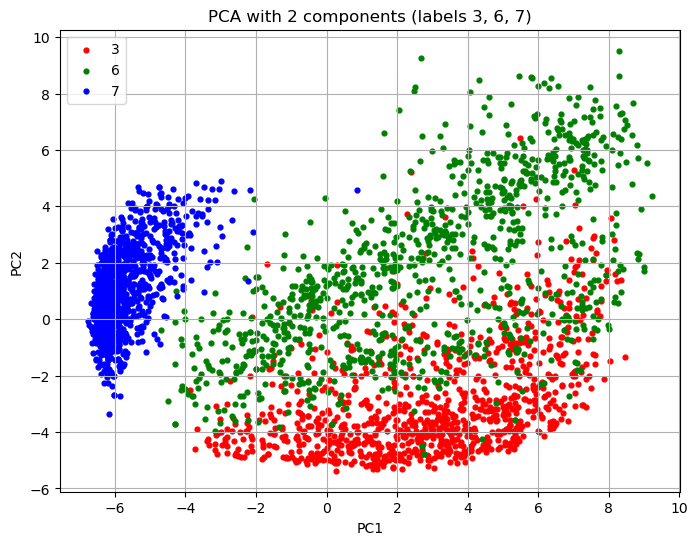

In [ ]:
#Answer to (9)
# Apply PCA to reduce selected samples to 2 dimensions
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_selected)

# Define colors for each digit
color_map = {
    3: 'red',
    6: 'green',
    7: 'blue'
}
# Plot each digit in its assigned color
plt.figure(figsize=(8,6))

plt.scatter(X_pca[y_selected==3, 0], X_pca[y_selected==3, 1], 
            color='red', label='3', s=12)

plt.scatter(X_pca[y_selected==6, 0], X_pca[y_selected==6, 1], 
            color='green', label='6', s=12)

plt.scatter(X_pca[y_selected==7, 0], X_pca[y_selected==7, 1], 
            color='blue', label='7', s=12)

plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('PCA with 2 components (labels 3, 6, 7)')
plt.legend()
plt.grid(True)
plt.show()

**(10) Using the K-means clustering algorithm to cluster the test images in (8) directly, using k=2, 3 and 4. And then use PCA with 2 components to visualize the test data samples with different colors representing different predicted clusters in a 2d plot for each k value. You need to produce three plots, one plot for each k value. [3 marks]**


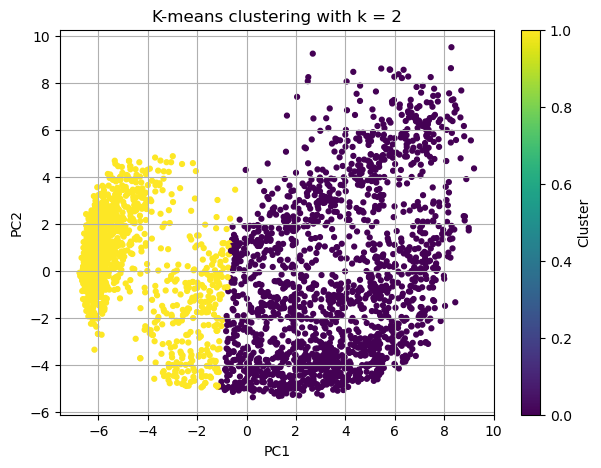

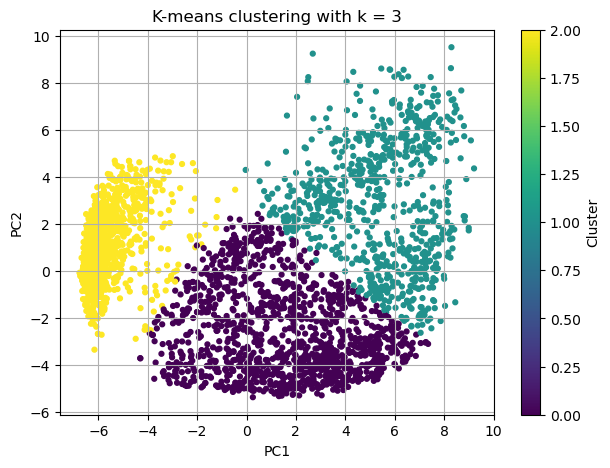

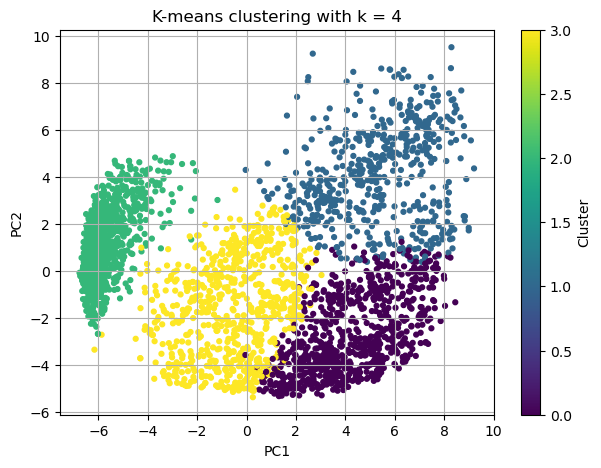

In [ ]:
#answer to (10)
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_selected)

# Perform K-means clustering for different k values and visualize
for k in [2, 3, 4]:
    kmeans = KMeans(n_clusters=k, random_state=0)
    clusters = kmeans.fit_predict(X_selected)

    # Scatter plot colored by predicted cluster
    plt.figure(figsize=(7,5))
    plt.scatter(X_pca[:,0], X_pca[:,1], c=clusters, cmap='viridis', s=12)
    plt.title(f'K-means clustering with k = {k}')
    plt.xlabel('PC1')
    plt.ylabel('PC2')
    plt.grid(True)
    plt.colorbar(label='Cluster')
    plt.show()

**(11) Calculate and print the respective Davies-Bouldin scores for k=2,3,4 in (10). Which k value produces the best clustering, according to the Davies-Bouldin score. Then answer: is it consistent with the ground truth number of clusters from fashion-MNIST?   [2 marks]**

In [ ]:
#answer to (11)
from sklearn.metrics import davies_bouldin_score

db_scores = {}

# Compute Davies-Bouldin score for different k values
for k in [2, 3, 4]:
    kmeans = KMeans(n_clusters=k, random_state=0)
    clusters = kmeans.fit_predict(X_selected)

    db = davies_bouldin_score(X_selected, clusters)
    db_scores[k] = db

    print(f"Davies-Bouldin score for k={k}: {db}")


# Find k with the lowest Davies-Bouldin score
best_k = min(db_scores, key=db_scores.get)
print("\nBest k according to Davies-Bouldin score:", best_k)


Davies-Bouldin score for k=2: 1.3941972201688329
Davies-Bouldin score for k=3: 1.6582333066865675
Davies-Bouldin score for k=4: 1.591692381045062

Best k according to Davies-Bouldin score: 2


Continued answer to (11)
The ground truth number of clusters in the selected dataset is 3 (digits 3, 6, and 7), so the Davies-Bouldin score does not match the actual number of classes

**(12) Calculate and print the respective silhouette_scores for k=2,3,4 in (10). Which k value produces the best clustering, according to the Silhouette score. Then answer: is it consistent with the ground truth number of clusters from fashion-MNIST?  [2 marks]**

In [ ]:
#answer to (12)
silhouette_scores = {}

# Compute Silhouette score for different k values
for k in [2, 3, 4]:
    kmeans = KMeans(n_clusters=k, random_state=0)
    predicted_clusters = kmeans.fit_predict(X_selected)

    score = silhouette_score(X_selected, predicted_clusters)
    silhouette_scores[k] = score

    print(f"Silhouette score for k={k}: {score}")

    
# Find k with the highest Silhouette score
best_k = max(silhouette_scores, key=silhouette_scores.get)
print("\nBest k according to Silhouette score:", best_k)

Silhouette score for k=2: 0.2752129906575254
Silhouette score for k=3: 0.2400544355299797
Silhouette score for k=4: 0.22373250992213797

Best k according to Silhouette score: 2


Continued answer to (12)
The ground truth number of clusters is 3 (digits 3, 6, 7), so the Silhouette score does not reflect the actual number of classes

**(13) Using the K-means clustering algorithm to cluster the first two components of PCA being applied to the tested images, using k=2, 3 and 4. And then compare the clustering results with those from (10) by making of 2 subplots for each value of k: one subplot with the clustering done on the whole images, one sublplot with the clustering done with just the two first components of the PCA. [2 marks]**


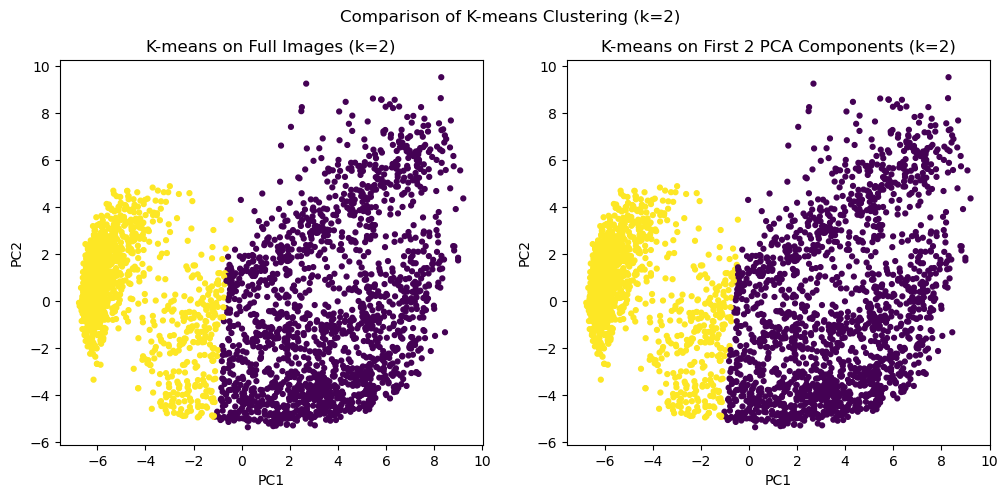

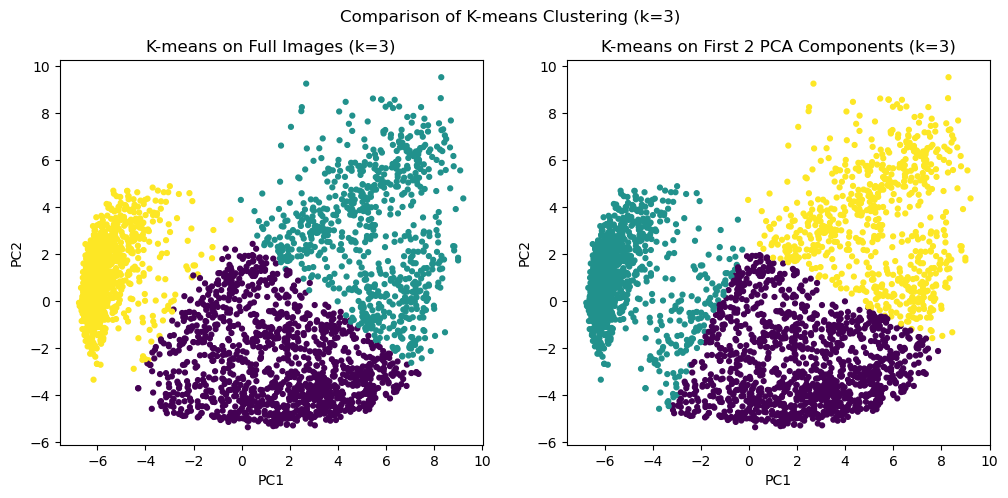

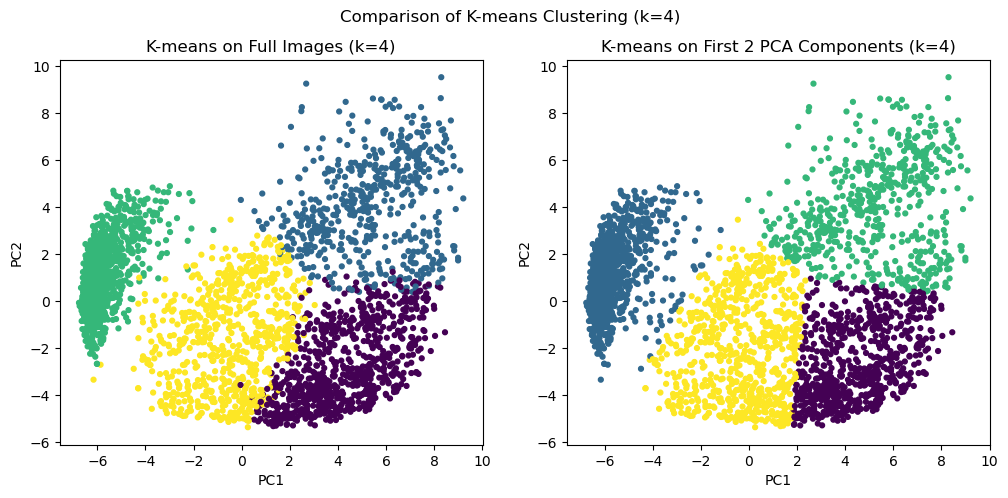

In [ ]:
#answer to (13)

k_values = [2, 3, 4]

for k in k_values:
    # K-means on the original selected images
    kmeans_full = KMeans(n_clusters=k, random_state=0)
    clusters_full = kmeans_full.fit_predict(X_selected)

    # K-means on the first two PCA components
    kmeans_pca = KMeans(n_clusters=k, random_state=0)
    clusters_pca = kmeans_pca.fit_predict(X_pca)

    # Create 2 subplots: full images vs PCAreduced
    fig, axs = plt.subplots(1, 2, figsize=(12,5))

    axs[0].scatter(X_pca[:,0], X_pca[:,1], c=clusters_full, cmap='viridis', s=12)
    axs[0].set_title(f'K-means on Full Images (k={k})')
    axs[0].set_xlabel('PC1')
    axs[0].set_ylabel('PC2')

    axs[1].scatter(X_pca[:,0], X_pca[:,1], c=clusters_pca, cmap='viridis', s=12)
    axs[1].set_title(f'K-means on First 2 PCA Components (k={k})')
    axs[1].set_xlabel('PC1')
    axs[1].set_ylabel('PC2')

    plt.suptitle(f'Comparison of K-means Clustering (k={k})')
    plt.show()

**(14) Compute the Silhouette scores for different k values in (13) and then compare with those obtained in (12). Answer: are the Silhouette scores obtained from the clustering of whole images consistent with the Silhouette scores obtained by clustering only the two first PCA components?  
[2 marks]**


In [ ]:
#answer to (14)
from sklearn.metrics import silhouette_score

silhouette_scores_full = {}
silhouette_scores_pca = {}

for k in k_values:
    # Clustering on full images
    kmeans_full = KMeans(n_clusters=k, random_state=0)
    clusters_full = kmeans_full.fit_predict(X_selected)
    silhouette_scores_full[k] = silhouette_score(X_selected, clusters_full)

    # Clustering on first 2 PCA components
    kmeans_pca = KMeans(n_clusters=k, random_state=0)
    clusters_pca = kmeans_pca.fit_predict(X_pca)
    silhouette_scores_pca[k] = silhouette_score(X_pca, clusters_pca)

# Print Silhouette scores for comparison
print("Silhouette scores for clustering on full images:", silhouette_scores_full)
print("Silhouette scores for clustering on first 2 PCA components:", silhouette_scores_pca)


# Identify best k for each case
best_k_full = max(silhouette_scores_full, key=silhouette_scores_full.get)
best_k_pca = max(silhouette_scores_pca, key=silhouette_scores_pca.get)
print(f"\nBest k for full images: {best_k_full}")
print(f"Best k for PCA 2 components: {best_k_pca}")


Silhouette scores for clustering on full images: {2: np.float64(0.2752129906575254), 3: np.float64(0.2400544355299797), 4: np.float64(0.22373250992213797)}
Silhouette scores for clustering on first 2 PCA components: {2: np.float64(0.51375924066582), 3: np.float64(0.5180230244210727), 4: np.float64(0.4895085878396698)}

Best k for full images: 2
Best k for PCA 2 components: 3


Continued answer to (14)
The Silhouette scores for clustering on full images are highest at k = 2, whereas the scores for clustering on the first two PCA components are highest at k = 3. This shows that the cluster structure in the reduced 2D PCA space is slightly different from that in the original high-dimensional space.

**(15) Let's compare the result of dimensionality reductions by PCA with 2 components and tSNE with 2 components. Apply PCA and tSNE to the test images of '3', '6', and '7', and then visualize the results in 2 subplots, one for each method. Use different colors to represent different real (ground truth) clusters.  [2 marks]**

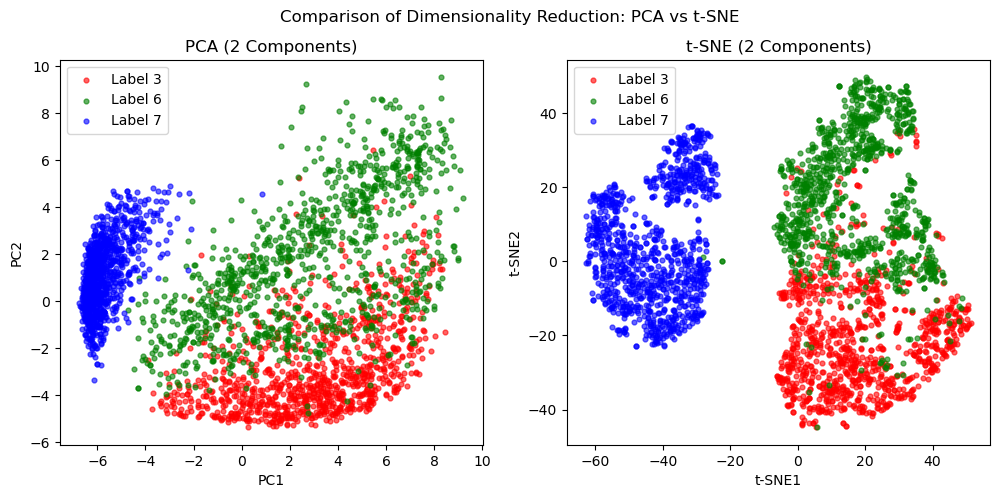

In [ ]:
#answer to (15)
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# Apply PCA to reduce to 2 components
pca_2d = PCA(n_components=2)
X_pca_2d = pca_2d.fit_transform(X_selected)

# Apply t-SNE to reduce to 2 components
tsne_2d = TSNE(n_components=2, random_state=0)
X_tsne_2d = tsne_2d.fit_transform(X_selected)

plt.figure(figsize=(12,5))

# Plot PCA results
plt.subplot(1,2,1)
for label, color in zip([3,6,7], ['red','green','blue']):
    idx = y_selected == label
    plt.scatter(X_pca_2d[idx,0], X_pca_2d[idx,1], c=color, label=f"Label {label}", s=12, alpha=0.6)
plt.title("PCA (2 Components)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend()


# Plot t-SNE results
plt.subplot(1,2,2)
for label, color in zip([3,6,7], ['red','green','blue']):
    idx = y_selected == label
    plt.scatter(X_tsne_2d[idx,0], X_tsne_2d[idx,1], c=color, label=f"Label {label}", s=12, alpha=0.6)
plt.title("t-SNE (2 Components)")
plt.xlabel("t-SNE1")
plt.ylabel("t-SNE2")
plt.legend()

plt.suptitle("Comparison of Dimensionality Reduction: PCA vs t-SNE")
plt.show()

## 2. Implementing DBSCAN clustering for classes of '3', '6', and '7' of fashion-MNIST dataset:


**(16) Firstly, use the DBSCAN clustering algorithm to cluster the test images directly by setting the eps parameter to 0.3 and the min_sample to 5. And then apply DBSCAN to cluster the first 2 PCA components of the test images by setting the eps parameter to 0.3 and the min_sample to 5.
Visualize the clustering results in two subplots for each k value and also print out the numbers of estimated clusters. [2 marks]**

Number of clusters (full images): 0
Number of clusters (PCA 2D): 33


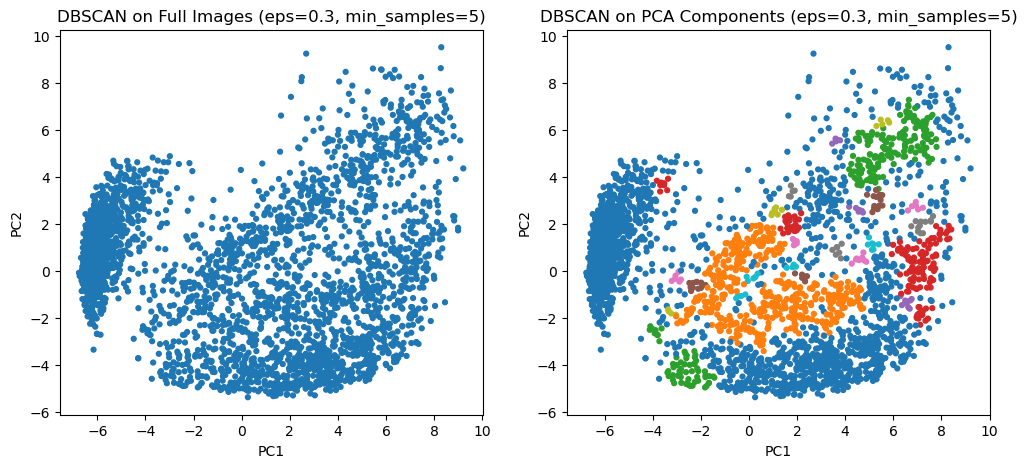

In [ ]:
#Answer for (16)

# DBSCAN on full images
from sklearn.cluster import DBSCAN
dbscan_full = DBSCAN(eps=0.3, min_samples=5)
clusters_full = dbscan_full.fit_predict(X_selected)


# DBSCAN on first 2 PCA components
dbscan_pca = DBSCAN(eps=0.3, min_samples=5)
clusters_pca = dbscan_pca.fit_predict(X_pca)

# Count number of clusters (excluding noise points labeled as -1)
n_clusters_full = len(set(clusters_full)) - (1 if -1 in clusters_full else 0)
n_clusters_pca = len(set(clusters_pca)) - (1 if -1 in clusters_pca else 0)

print(f"Number of clusters (full images): {n_clusters_full}")
print(f"Number of clusters (PCA 2D): {n_clusters_pca}")

# Visualization in 2 subplots
fig, axs = plt.subplots(1,2,figsize=(12,5))

axs[0].scatter(X_pca[:,0], X_pca[:,1], c=clusters_full, cmap='tab10', s=12)
axs[0].set_title(f'DBSCAN on Full Images (eps=0.3, min_samples=5)')
axs[0].set_xlabel('PC1')
axs[0].set_ylabel('PC2')

axs[1].scatter(X_pca[:,0], X_pca[:,1], c=clusters_pca, cmap='tab10', s=12)
axs[1].set_title(f'DBSCAN on PCA Components (eps=0.3, min_samples=5)')
axs[1].set_xlabel('PC1')
axs[1].set_ylabel('PC2')

plt.show()

**(17) Changing the eps parameter in (16) to 0.5 and 1, and briefly summarize your observations of the experimental results in terms of the stability of the DBSCAN method in comparison to K-means: is DBSCAN more or less stable than K-means, when it comes to changing hyperparameters? [2 marks]**

In [ ]:
eps_values = [0.3, 0.5, 1]

for eps in eps_values:
    dbscan = DBSCAN(eps=eps, min_samples=5)  
    clusters = dbscan.fit_predict(X_pca)
    n_clusters = len(set(clusters)) - (1 if -1 in clusters else 0)
    print(f"eps={eps}, number of clusters: {n_clusters}")

eps=0.3, number of clusters: 33
eps=0.5, number of clusters: 5
eps=1, number of clusters: 1


Answer to (17)
As eps increases, DBSCAN mergers more points into clusters. This results in the total number of clusters being reduced showing that DBSCAN is sensitive to hyperparameters, especially eps. This is different from K-means because it always produces exactly k-clusters.

**(18) Compare the performance of K-means and DBSCAN when clustering the data points obtained by applying tSNE with 2 components on test images of classes '3', '6', and '7'.**

**Set k in K-means to k=3. Play with different values of (eps, min_samples) in DBSCAN to find a proper setup. Visualize the clustering results in 2 subplots. Answer: which method is more robust from the above results? How did you arrive at that conclusion? [2 marks]**

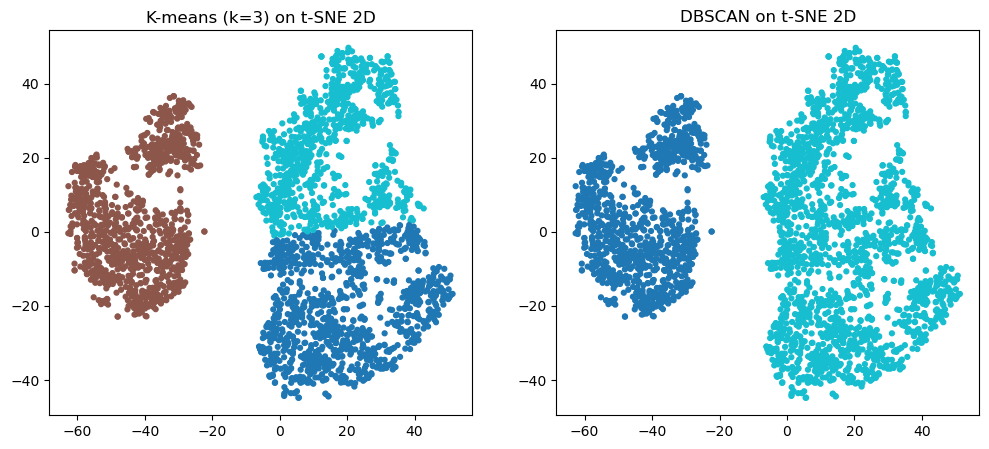

In [ ]:
#Answer to (18)
from sklearn.manifold import TSNE

X_tsne = TSNE(n_components=2, random_state=0).fit_transform(X_selected)

kmeans = KMeans(n_clusters=3, random_state=0)
clusters_kmeans = kmeans.fit_predict(X_tsne)

dbscan = DBSCAN(eps=5, min_samples=5)
clusters_dbscan = dbscan.fit_predict(X_tsne)

fig, axs = plt.subplots(1,2,figsize=(12,5))
axs[0].scatter(X_tsne[:,0], X_tsne[:,1], c=clusters_kmeans, cmap='tab10', s=12)
axs[0].set_title('K-means (k=3) on t-SNE 2D')
axs[1].scatter(X_tsne[:,0], X_tsne[:,1], c=clusters_dbscan, cmap='tab10', s=12)
axs[1].set_title('DBSCAN on t-SNE 2D')
plt.show()

Continued answer to (18).
K-means produces 3 clusters as expected and DBSCAN has produced 2. K-means is more robust here because it is less sensitive to hyperparameter while DBSCAN is flexible but can be unstable

**(19) Implement bisecting K-means algorithm and Gausian mixture models to cluster the 2 components of tSNE for the test images of classes '3', '6', and '7'. Set the number of clusters to be 3.    [2 marks]**

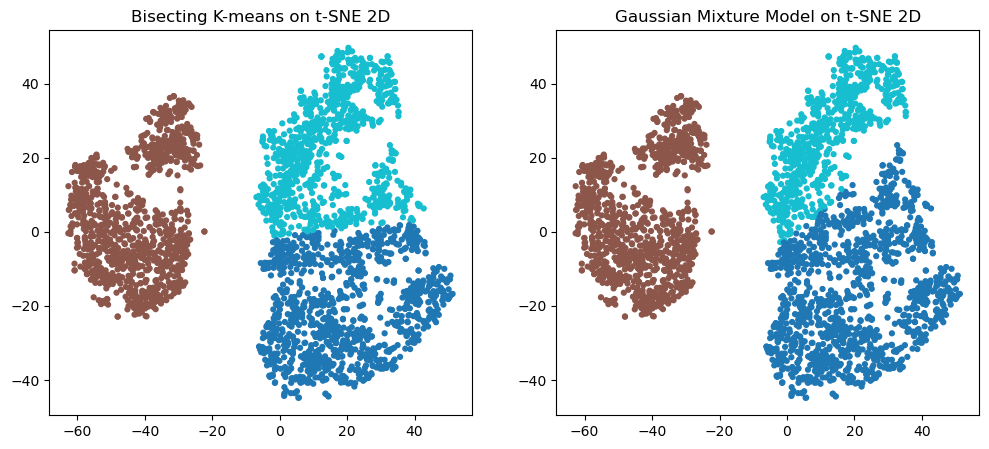

In [ ]:
# Answer to (19)
from sklearn.mixture import GaussianMixture
from sklearn.cluster import BisectingKMeans

bisecting_kmeans = KMeans(n_clusters=3, random_state=0)
clusters_bisecting = bisecting_kmeans.fit_predict(X_tsne)

gmm = GaussianMixture(n_components=3, random_state=0)
clusters_gmm = gmm.fit_predict(X_tsne)

fig, axs = plt.subplots(1,2,figsize=(12,5))
axs[0].scatter(X_tsne[:,0], X_tsne[:,1], c=clusters_bisecting, cmap='tab10', s=12)
axs[0].set_title('Bisecting K-means on t-SNE 2D')
axs[1].scatter(X_tsne[:,0], X_tsne[:,1], c=clusters_gmm, cmap='tab10', s=12)
axs[1].set_title('Gaussian Mixture Model on t-SNE 2D')
plt.show()

**(20). Usually, DBSCAN takes longer than K-means to run, and the time it takes to run is affected by the eps parameter. Explain why that is the case. [4 marks]**

Answer to (20):
DBSCAN works by checking how close each point is to its surrounding points, which means it has to measure a lot of distances. When the value of eps increases, the algorithm ends up considering a wider area for every point, so the number of distance checks grows even more. This makes DBSCAN slower, especially on dense datasets. In contrast, K-means runs much faster because it follows a simple routine. It assigns each point to the nearest centroid and then updates the positions of these centroids. The amount of work mostly depends on how many clusters you choose and the number of data points, but it scales in a predictable and efficient way. For this reason, DBSCAN’s running time is strongly influenced by the choice of eps and by how packed the data is, while K-means stays relatively stable and usually finishes quicker

**(21). Provide an example of one case in which it might be better to use DBSCAN rather than K-means, and an example of one case in which it might be better to use K-means rather than DBSCAN. Explain why, in both cases. [4 marks]**

Answer to (21):
If you are dealing with data that forms odd or uneven shapes such as mapping the locations of people across a city to find natural gathering areas DBSCAN performs well because it can discover clusters of any shape and can also mark outliers as noise. On the other hand, K-means is more suitable when the clusters are roughly circular or evenly separated, and when the number of groups is already known. A common example is dividing customers into a small number of well-defined segments. In this case, K-means is fast, easy to interpret, and works reliably when the clusters are compact and fairly symmetric.

_____________________

# Part C – Classification and Regression [32 marks]

## 1 Implement a multi-class Logistic Regression classifier for fashion-MNIST dataset.  [20 marks]

**(22) Load "train-labels-idx1-ubyte.gz" and "train-images-idx3-ubyte.gz". In the variable X_tmp (see the code below), every row represents a greyscale image, and every one of the 784 columns represent a pixel value. 784 = 28 x 28. So each image is size 28*28.**

**First, load the two files "train-labels-idx1-ubyte.gz" and "train-images-idx3-ubyte.gz". Then, perform train-test-split to prepare both the training data in terms of (X_train, y_train) and test data in terms of (X_test, y_test). The code for this question is provided below to faciliate the implementation for the following questions. [0 mark]**

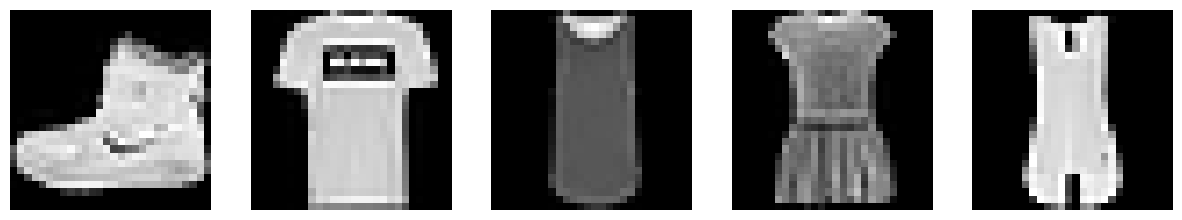

In [ ]:
# answer for (22). You may need to change the path for "train-labels-idx1-ubyte.gz" and "train-images-idx3-ubyte.gz".
import pandas as pd
from sklearn.model_selection import train_test_split
from matplotlib import pyplot as plt
import numpy as np


def load_mnist(path, kind='train'):
    import os
    import gzip
    import numpy as np

    """Load fashion-MNIST data from `path`"""
    labels_path = os.path.join(path,
                               '%s-labels-idx1-ubyte.gz'
                               % kind)
    images_path = os.path.join(path,
                               '%s-images-idx3-ubyte.gz'
                               % kind)

    with gzip.open(labels_path, 'rb') as lbpath:
        labels = np.frombuffer(lbpath.read(), dtype=np.uint8,
                               offset=8)

    with gzip.open(images_path, 'rb') as imgpath:
        images = np.frombuffer(imgpath.read(), dtype=np.uint8,
                               offset=16).reshape(len(labels), 784)

    return images, labels


X_tmp, y_tmp = load_mnist('/Users/chiyevo/Desktop/Coursework/ML 2/COM1011 Assessment- Datasets-20251128/', kind='train')

# normalization
X_tmp = X_tmp/255.0


plt.figure(figsize=(15,3))
for i in range(5):
  image = X_tmp[i,:].reshape(28,28)
  plt.subplot(1, 5, i+1)
  plt.imshow(image, cmap='gray')
  plt.axis('off')
plt.show()

X_train, X_test, y_train, y_test = train_test_split(X_tmp, y_tmp, test_size=0.2, random_state=1)

**(23) Implement a two-class Logistic Regression classifer for classes with labels 4 and 6 in fashion-MNIST by using LogisticRegression from `sklearn.linear_model`. Set random_state to 42, solver='sag' and max_iter=200 in LogisticRegression- (look at the documentation online if needed). Print both the training and test classfication accuracices. [1 mark]**

In [ ]:
#answer to (23)
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Select only the samples with labels 4 and 6
train_mask = (y_train == 4) | (y_train == 6)
test_mask = (y_test == 4) | (y_test == 6)

X_train_46 = X_train[train_mask]
y_train_46 = y_train[train_mask]
X_test_46 = X_test[test_mask]
y_test_46 = y_test[test_mask]

# Test different max_iter values to ensure convergence
max_iter_values_23 = [300, 500]

train_acc_23 = []
test_acc_23 = []

for m in max_iter_values_23:
    print(f"\nRunning Logistic Regression with max_iter = {m}")

    # Initialize and fit Logistic Regression model
    model = LogisticRegression(
        solver='sag',
        random_state=42,
        max_iter=m
    )

    model.fit(X_train_46, y_train_46)

    # Predict on training and test data
    train_pred = model.predict(X_train_46)
    test_pred = model.predict(X_test_46)

    # Compute accuracies
    train_accuracy = accuracy_score(y_train_46, train_pred)
    test_accuracy = accuracy_score(y_test_46, test_pred)

    print(f"Training Accuracy: {train_accuracy}")
    print(f"Test Accuracy:     {test_accuracy}")

    train_acc_23.append(train_accuracy)
    test_acc_23.append(test_accuracy)


Running Logistic Regression with max_iter = 300


/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


Training Accuracy: 0.9009624340266997
Test Accuracy:     0.881471972614463

Running Logistic Regression with max_iter = 500
Training Accuracy: 0.9010659215564525
Test Accuracy:     0.881471972614463


**(24) Test solver='sag', random_state=42, and max_iter={300, 500} in (23). Print both the training and test classfication accuracices. [2 marks]**

In [ ]:
# answer to (24)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, precision_recall_fscore_support

# Select only the samples with labels 4 and 6
train_mask = (y_train == 4) | (y_train == 6)
test_mask  = (y_test == 4) | (y_test == 6)

X_train_46 = X_train[train_mask]
y_train_46 = y_train[train_mask]

X_test_46 = X_test[test_mask]
y_test_46 = y_test[test_mask]

# Test different max_iter values
max_iter_values = [300, 500]

for m in max_iter_values:
    print(f"\nTraining Logistic Regression with max_iter = {m}")

    # Initialize Logistic Regression with solver 'sag'
    model = LogisticRegression(
        solver='sag',
        random_state=42,
        max_iter=m
    )
    
    model.fit(X_train_46, y_train_46)   

     # Predictions and accuracy
    train_pred = model.predict(X_train_46)
    train_acc = accuracy_score(y_train_46, train_pred)
    

    test_pred = model.predict(X_test_46)
    test_acc = accuracy_score(y_test_46, test_pred)
    
    print(f"Training Accuracy: {train_acc}")
    print(f"Test Accuracy:     {test_acc}")


Training Logistic Regression with max_iter = 300


/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


Training Accuracy: 0.9009624340266997
Test Accuracy:     0.881471972614463

Training Logistic Regression with max_iter = 500
Training Accuracy: 0.9010659215564525
Test Accuracy:     0.881471972614463


**(25) Plot both the training and test accuracies for the maximum iterations of 200, 300,  500 being set in LogisticRegression, based on the results from (23) and (24). Put the two curves (one for the training curve and the other for the test curve) in the same 2d plot for easy comparison. Make X axis be the number of maximum iterations (200, 300, 500) and the y axis be the accuracy. [1 mark]**

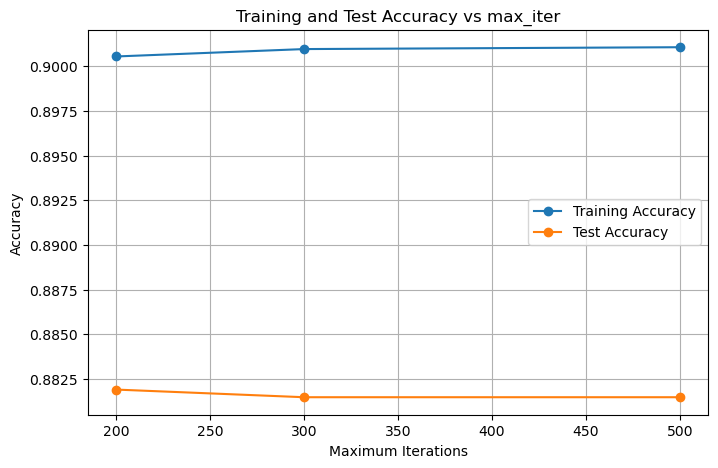

In [ ]:
# Answer to (25)

train_acc_200 = 0.9005484839076892
test_acc_200  = 0.8818998716302953

train_acc_300 = 0.9009624340266997
test_acc_300  = 0.881471972614463

train_acc_500 = 0.9010659215564525
test_acc_500  = 0.881471972614463

max_iter_values = [200, 300, 500]
training_accs = [train_acc_200, train_acc_300, train_acc_500]
testing_accs  = [test_acc_200, test_acc_300, test_acc_500]


plt.figure(figsize=(8,5))
plt.plot(max_iter_values, training_accs, marker='o', label='Training Accuracy')
plt.plot(max_iter_values, testing_accs, marker='o', label='Test Accuracy')

plt.xlabel("Maximum Iterations")
plt.ylabel("Accuracy")
plt.title("Training and Test Accuracy vs max_iter")
plt.legend()
plt.grid(True)
plt.show()

**(26) Three classification models have been obtained from (23) and (24) by setting different values for the hyper-parameter max_iter. Which model should we choose? Explain why. [1 mark]**

**What is overfitting? Why is that a problem, and how can one avoid it? [3 marks]**


**Does the plot in (25) exhibit over-fitting? Explain why. [1 mark]**   

Answer to (26):

Choose max_iter = 200. It has the best test accuracy and trains fastest. Higher max_iter values do not improve performance.

Overfitting is when a model learns the training data too closely. It is a problem because it performs poorly on new, unseen data. It can be avoided using regularisation, simpler models, more data, early stopping or cross validation.

No, the plot does not show overfitting. Training and test accuracies are almost the same. There is no large gap between the two curves.

**(27) Let's do some data augmentation to improve the test performance in (23) and (24). In doing so, prepare additional training data for class 4 and 6 of fashion-MNIST by flipping each image horizontally using a library like numpy.flip. Display one original image alongside its flipped version to demonstrate the augmentation.   [2 marks]**

**Then, use both the original training data and the flipped training data to train the two-class Logistic Regression classifer. Print out the training and test accuracies for max_iter = {200, 300, 500}.  [2 marks]**

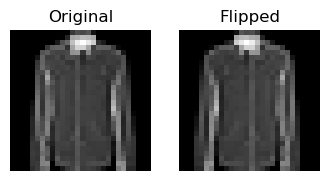


Training Logistic Regression with max_iter = 200 (with augmented data)


/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


Training Accuracy: 0.8888026492807617
Test Accuracy:     0.8789045785194695

Training Logistic Regression with max_iter = 300 (with augmented data)


/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


Training Accuracy: 0.888854393045638
Test Accuracy:     0.8789045785194695

Training Logistic Regression with max_iter = 500 (with augmented data)
Training Accuracy: 0.888854393045638
Test Accuracy:     0.8789045785194695


In [ ]:
# Answer to (27)
from sklearn.linear_model import LinearRegression
from sklearn.metrics import accuracy_score, confusion_matrix, precision_recall_fscore_support
from scipy.ndimage import rotate

train_mask = (y_train == 4) | (y_train == 6)
X_train_46 = X_train[train_mask]
y_train_46 = y_train[train_mask]

test_mask  = (y_test == 4) | (y_test == 6)
X_test_46 = X_test[test_mask]
y_test_46 = y_test[test_mask]

# Flip images horizontally
X_train_aug = np.flip(X_train_46.reshape(-1,28,28), axis=2)  
X_train_aug = X_train_aug.reshape(-1, 28*28)                 

# Combine original and augmented data
X_train_combined = np.vstack([X_train_46, X_train_aug])
y_train_combined = np.hstack([y_train_46, y_train_46])

# Display original and flipped image
plt.figure(figsize=(4,2))
plt.subplot(1,2,1)
plt.imshow(X_train_46[0].reshape(28,28), cmap='gray')
plt.title("Original")
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(X_train_aug[0].reshape(28,28), cmap='gray')
plt.title("Flipped")
plt.axis('off')

plt.show()

# Train Logistic Regression with augmented data
max_iter_values = [200, 300, 500]

for m in max_iter_values:
    print(f"\nTraining Logistic Regression with max_iter = {m} (with augmented data)")
    
    model = LogisticRegression(
        solver='sag',
        random_state=42,
        max_iter=m
    )
    
    model.fit(X_train_combined, y_train_combined)
    
    # Training accuracy
    train_pred = model.predict(X_train_combined)
    train_acc = accuracy_score(y_train_combined, train_pred)
    
    # Test accuracy
    test_pred = model.predict(X_test_46)
    test_acc = accuracy_score(y_test_46, test_pred)
    
    print(f"Training Accuracy: {train_acc}")
    print(f"Test Accuracy:     {test_acc}")

**(28) In general, is the image-flip technique a reasonable approach for the considered classification problem? Provide your reasoning. [2 marks]**

**Is the test accuracy obtained in (27) better than those in (23) and (24)? [1 mark]**

**Consider three approaches: 1-change to advanced machine learning models, 2-employ other data augmentation techniques, 3-employ other data pre-processing techniques.  What do you think is the most effective approach to improve the test performance ? Why. [2 marks]**

**Elaborate on the most effective approach you have chosen by providing more detailed suggestions. [2 marks]**

Answer to (28):
Yes, it is reasonable for this problem. Flipping horizontally creates new training examples while keeping the label the same. Fashion-MNIST items like shoes or shirts can appear in either orientation. It helps the model generalize to slightly different images.

The test accuracies obtained in (27) with the augmented data are slightly lower than those in (23) and (24).


Change to advanced machine learning models is likely the most effective because logistic Regression is simple and linear, and more advanced models can capture complex patterns in images. Data augmentation and preprocessing help, but model capacity has the largest impact.

Use Convolutional Neural Networks (CNNs) to learn spatial features automatically. Try deeper networks with more layers and filters. Apply dropout and batch normalization to improve generalization. Combine CNNs with data augmentation like flipping, rotation, and zoom. Train using an Adam optimizer with proper learning rate schedules.

## 2 Implement regression for the housing dataset.  [12 marks]

**(29) Check how normalization affects the regression performance with the dataset "housing.csv".**

**Firstly, visualize the correlation matrix in terms of the heat map for all the 14 features. [0.5 mark]**

**Secondly, implement a Linear model that use only the 'CRIM' and 'RM' to predict 'TAX' without normalization. In doing so, split the data into training and test datasets. Report both the training and test errors in terms of mean squared error (MSE). [0.5 mark]**

**Thirdly, do normalization (refer to the operation of scaling each feature to be in the range of [0,1]) to the data, and then implement a Linear model that use normalized 'CRIM' and normalized 'RM' to predict normalized 'TAX'. Report both the training and test errors.  What conclusions can you draw by comparing the above prediction results regarding the impact of normalization? [1 mark]**





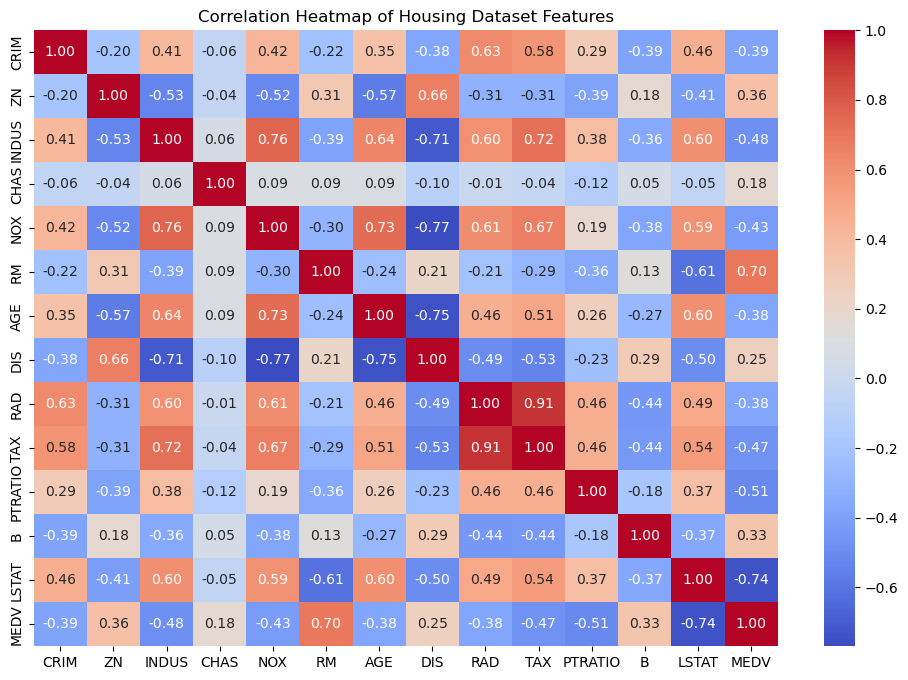

Training MSE (without normalization): 17591.13
Test MSE (without normalization):     19360.27
Training MSE (with normalization): 0.0641
Test MSE (with normalization):     0.0705


In [ ]:
# Answer to (29)
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
import math
import pandas as pd
from matplotlib import pyplot as plt


column_names = ['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT', 'MEDV']

regression_data = pd.read_csv('/Users/chiyevo/Desktop/Coursework/ML 2/COM1011 Assessment- Datasets-20251128/housing.csv')


correlation_matrix = regression_data.corr()

plt.figure(figsize=(12,8))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap of Housing Dataset Features")
plt.show()

# Select features and target
X = regression_data[['CRIM', 'RM']].values
y = regression_data['TAX'].values

# Split into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train Linear Regression
lr = LinearRegression()
lr.fit(X_train, y_train)

# Predictions
y_train_pred = lr.predict(X_train)
y_test_pred  = lr.predict(X_test)

# Compute MSE
mse_train = mean_squared_error(y_train, y_train_pred)
mse_test  = mean_squared_error(y_test, y_test_pred)

print(f"Training MSE (without normalization): {mse_train:.2f}")
print(f"Test MSE (without normalization):     {mse_test:.2f}")

# Min-max normalization to [0,1]
X_min = X.min(axis=0)
X_max = X.max(axis=0)
X_norm = (X - X_min) / (X_max - X_min)

y_min = y.min()
y_max = y.max()
y_norm = (y - y_min) / (y_max - y_min)

# Split normalized data
X_train_norm, X_test_norm, y_train_norm, y_test_norm = train_test_split(
    X_norm, y_norm, test_size=0.2, random_state=42
)

# Train Linear Regression on normalized data
lr_norm = LinearRegression()
lr_norm.fit(X_train_norm, y_train_norm)

# Predictions
y_train_pred_norm = lr_norm.predict(X_train_norm)
y_test_pred_norm  = lr_norm.predict(X_test_norm)

# Compute MSE
mse_train_norm = mean_squared_error(y_train_norm, y_train_pred_norm)
mse_test_norm  = mean_squared_error(y_test_norm, y_test_pred_norm)

print(f"Training MSE (with normalization): {mse_train_norm:.4f}")
print(f"Test MSE (with normalization):     {mse_test_norm:.4f}")


Continued answer to (29):
After normalization, both the training and test mean squared errors are smaller and more stable. This shows that scaling improves numerical stability and helps the optimization converge more reliably. Linear regression performs better when features are on similar scales, as it reduces the influence of variables with larger ranges and allows the model to weight them appropriately.

**(30) Check how correlation strength affects the regression performance with the dataset "housing.csv".**

**Use normlized "CRIM" and normalized "ZN" to predict normalized "TAX" by using a linear model. Print out the training and test mean squared error. Remember using the same random_state and the same test_size when running the train_test_split function from sklearn.model_selection.   [1 mark]**

**Use normlized "CRIM" and normalized "INDUS" to predict normalized "TAX" by using a linear model. Print out the training and test mean squared error. Remember using the same random_state and the same test_size when running the train_test_split function from sklearn.model_selection.   [1 mark]**

In [ ]:
# Answer to (30)

# Use same train-test split parameters
test_size = 0.2
random_state = 42


X_crim_zn = regression_data[['CRIM', 'ZN']].values
X_crim_zn_norm = (X_crim_zn - X_crim_zn.min(axis=0)) / (X_crim_zn.max(axis=0) - X_crim_zn.min(axis=0))

y_tax_norm = (regression_data['TAX'].values - regression_data['TAX'].min()) / (regression_data['TAX'].max() - regression_data['TAX'].min())

X_train1, X_test1, y_train1, y_test1 = train_test_split(
    X_crim_zn_norm, y_tax_norm, test_size=test_size, random_state=random_state
)

lr1 = LinearRegression()
lr1.fit(X_train1, y_train1)

y_train1_pred = lr1.predict(X_train1)
y_test1_pred  = lr1.predict(X_test1)

mse_train1 = mean_squared_error(y_train1, y_train1_pred)
mse_test1  = mean_squared_error(y_test1, y_test1_pred)

print("CRIM + ZN -> TAX")
print(f"Training MSE: {mse_train1:.4f}")
print(f"Test MSE:     {mse_test1:.4f}\n")


X_crim_indus = regression_data[['CRIM', 'INDUS']].values
X_crim_indus_norm = (X_crim_indus - X_crim_indus.min(axis=0)) / (X_crim_indus.max(axis=0) - X_crim_indus.min(axis=0))

X_train2, X_test2, y_train2, y_test2 = train_test_split(
    X_crim_indus_norm, y_tax_norm, test_size=test_size, random_state=random_state
)

lr2 = LinearRegression()
lr2.fit(X_train2, y_train2)

y_train2_pred = lr2.predict(X_train2)
y_test2_pred  = lr2.predict(X_test2)

mse_train2 = mean_squared_error(y_train2, y_train2_pred)
mse_test2  = mean_squared_error(y_test2, y_test2_pred)

print("CRIM + INDUS -> TAX")
print(f"Training MSE: {mse_train2:.4f}")
print(f"Test MSE:     {mse_test2:.4f}")


CRIM + ZN -> TAX
Training MSE: 0.0636
Test MSE:     0.0665

CRIM + INDUS -> TAX
Training MSE: 0.0404
Test MSE:     0.0354


**(31) What conclusions can you draw by comparing the test errors of (29) and (30) regarding the impact of the correlation strength (check the heat map shown above)? [1 mark]**

Answer to (31):

We can see that using features with stronger correlation with the target leads to lower errors. In (30), the combination CRIM + INDUS (more correlated with TAX) gives a test MSE of 0.0354, which is lower than 0.0665 for CRIM + ZN (less correlated). This shows that even after normalization (as in 29), choosing features that are more strongly correlated with the target improves regression performance.

**(32) Convert a regression problem to a classification problem of 10 classes.**

**First pre-processing the data for "TAX" to be in the range of [0,10) denoted as yy in the data type of float. Then tranform (via the rounding opertion) yy into the data type of integer within {0,1,2,.., 9} denoted as y. [1 mark]**

**Obtain training and test datasets from  normlized "CRIM", normalized "INDUS", and the ground truth labels y. Then implement a Logistic classifer and report the training and test accuracies.  Set random_state to 42, solver='sag' and max_iter=200 in LogisticRegression. [1 mark]**

**Rescale the prediced labels from the Logistic classifer to the range of [0, 1] and then compute and print out the mean squqred errors (MSEs) with respect to the normalized ground truth "TAX" for both training and test datasets.  [1 mark]**

**Compare the obtained MSEs with those in (30). Which method produces lower MSE for test dataset?  Which method produces lower MSE for training dataset? Do you think converting a regression problem to a classification problem is a resonable approch in general? [1 mark]**


In [ ]:
#Answer to (32)
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score



# Normalize TAX to [0,10)
yy = (regression_data['TAX'].values - regression_data['TAX'].min()) / (regression_data['TAX'].max() - regression_data['TAX'].min()) * 10

# Round and convert to integers 0-9
y = np.round(yy).astype(int)


X = regression_data[['CRIM', 'INDUS']].values
X_norm = (X - X.min(axis=0)) / (X.max(axis=0) - X.min(axis=0))

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X_norm, y, test_size=0.2, random_state=42)


clf = LogisticRegression(random_state=42, solver='sag', max_iter=200, multi_class='multinomial')
clf.fit(X_train, y_train)

# Training and test accuracies
train_acc = clf.score(X_train, y_train)
test_acc  = clf.score(X_test, y_test)

print(f"Training Accuracy: {train_acc:.4f}")
print(f"Test Accuracy:     {test_acc:.4f}")

y_train_pred_class = clf.predict(X_train) / 10
y_test_pred_class  = clf.predict(X_test) / 10

# Normalized TAX for comparison
y_train_norm = (y_train / 10).astype(float)  # since y_train is 0-9
y_test_norm  = (y_test / 10).astype(float)

# Compute MSE
mse_train_class = mean_squared_error(y_train_norm, y_train_pred_class)
mse_test_class  = mean_squared_error(y_test_norm, y_test_pred_class)

print(f"Training MSE (classification approach): {mse_train_class:.4f}")
print(f"Test MSE (classification approach):     {mse_test_class:.4f}")



Training Accuracy: 0.5371
Test Accuracy:     0.5882
Training MSE (classification approach): 0.0454
Test MSE (classification approach):     0.0281


/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


Continued answer to (32)

The regression approach from (30) produces lower test and training MSEs than converting the problem into a 10-class classification problem. The classification approach turns the continuous target values into categories, which introduces rounding errors and reduces precision. This shows that converting a regression problem into classification is generally not ideal if precise numeric predictions are needed, though it can be used when only coarse categories are required.


**(33) Convert the same regression problem in (32) to a classification problem of 100 classes. Set random_state to 42, solver='sag' and max_iter=200 in LogisticRegression. Report the MSEs for both training and test datasets.  [1 mark]**

**Compare the obtained MSEs with those of the classification method in (32).
Is the performance get better? [1 mark]**

**How to futher improve the peformance of the classification method? [1 mark]**

In [ ]:
#Answer to (33)

yy_100 = (regression_data['TAX'].values - regression_data['TAX'].min()) / (regression_data['TAX'].max() - regression_data['TAX'].min()) * 100
y_100 = np.round(yy_100).astype(int)

X_train, X_test, y_train_100, y_test_100 = train_test_split(X_norm, y_100, test_size=0.2, random_state=42)


clf_100 = LogisticRegression(random_state=42, solver='sag', max_iter=200)
clf_100.fit(X_train, y_train_100)


train_acc_100 = clf_100.score(X_train, y_train_100)
test_acc_100  = clf_100.score(X_test, y_test_100)
print(f"Training Accuracy: {train_acc_100:.4f}")
print(f"Test Accuracy:     {test_acc_100:.4f}")

y_train_pred_100 = clf_100.predict(X_train) / 100
y_test_pred_100  = clf_100.predict(X_test) / 100

y_train_norm = y_train_100 / 100
y_test_norm  = y_test_100 / 100

mse_train_100 = mean_squared_error(y_train_norm, y_train_pred_100)
mse_test_100  = mean_squared_error(y_test_norm, y_test_pred_100)

print(f"Training MSE (100-class approach): {mse_train_100:.4f}")
print(f"Test MSE (100-class approach):     {mse_test_100:.4f}")


Training Accuracy: 0.3094
Test Accuracy:     0.3333
Training MSE (100-class approach): 0.1096
Test MSE (100-class approach):     0.1170


Continued answer to (33)

The 100-class classification approach produces higher MSEs than the 10-class method from (32). For the training data, MSE increased from 0.0454 to 0.1096, and for the test data, it increased from 0.0281 to 0.1170. This means the performance got worse when increasing the number of classes.

To further improve performance, you could reduce the number of classes, use more informative features, or apply more advanced models such as neural networks. You could also try better data preprocessing or normalization, or augment the dataset to give the classifier more examples to learn from.

________________

# Part D – Dimensionality reduction [9 marks]

Consider a scenario where you are working with a high-dimensional dataset derived from an ecological study to classify the health status of tree species based on traits such as leaf size, trunk diameter, and soil nutrient levels. The data is expected to have both linear and non-linear relationships, and you aim to reduce the dimensionality for visualization to identify potential clusters (e.g., healthy vs. diseased trees) and preprocessing for a downstream classification task.

**(34)	Discuss the advantages and disadvantages of using PCA, t-SNE, and UMAP for the visualization purpose, considering factors such as the preservation of local and global structures, computational efficiency, and the potential introduction of artifacts. [3 marks]**

Answer to (34)

PCA is a linear method that efficiently reduces dimensionality by capturing the directions of maximum variance. It is computationally fast, easy to implement, and deterministic, meaning results are reproducible. However, PCA can fail to capture non-linear relationships and may obscure complex clusters if the variance is spread across multiple components.

t-SNE excels at preserving local structures, so it is very effective for visualizing clusters in high-dimensional data, even when relationships are non-linear. Its main disadvantage is computational cost for large datasets, and it can distort global structures, making the distances between clusters less interpretable. Additionally, t-SNE is stochastic, so repeated runs can produce slightly different visualizations.

UMAP balances local and global structure better than t-SNE and is generally faster on larger datasets. It can reveal both cluster formation and broader data patterns. However, like t-SNE, UMAP is stochastic and sensitive to hyperparameters, which may introduce artifacts if not carefully tuned.


**(35)	Explain how the choice between these dimensionality reduction techniques might change when, after visualising, you want to do the preprocessing for the machine learning task. [3 marks]**

Answer to (35)
When the goal is preprocessing for downstream machine learning, PCA is often preferred because it preserves global variance and produces a linear transformation, which can be used directly as input features for models. t-SNE and UMAP are mainly for visualization; their embeddings do not guarantee that distances or relationships in the reduced space are meaningful for model training. Using t-SNE or UMAP features for classification can sometimes lead to poorer performance because they prioritize local relationships over overall structure.

**(36).	Discuss the role of interpretability and stability in the choice of dimensionality reduction technique for both tasks. How might the stochastic nature of t-SNE and UMAP influence the reproducibility of your analyses, and how can PCA's linear assumptions limit its usefulness in capturing complex relationships in the data? [3 marks]**

Answer to (36)
Interpretability is important if you want to understand which features contribute to separation in the reduced space. PCA is interpretable since each component is a linear combination of original features. t-SNE and UMAP are harder to interpret because the axes in the low-dimensional space have no direct meaning. Stability matters for reproducibility: PCA is deterministic, so repeated analyses produce identical results, whereas t-SNE and UMAP are stochastic, so results may vary between runs. This stochasticity can be mitigated by setting a random seed, but some variation will always remain. Additionally, PCA’s linear assumptions limit its ability to capture non-linear relationships, so complex ecological interactions might not be well represented in PCA embeddings, while t-SNE and UMAP can capture these patterns more effectively.

________________

# Part E – Applications of Machine Learning [17 marks]

**(37).	In the context of classifying MNIST digits 7 and 8, explain why a classifier might struggle to distinguish between these digits even with high overall accuracy. Suggest two evaluation metrics that would better reveal this issue, and justify their use. [3 marks]**

Answer to (37)
Even if a classifier achieves high overall accuracy on MNIST, it might still struggle to distinguish between digits 7 and 8 because these two digits can be visually similar in certain handwriting styles. Misclassifying just a few of these ambiguous examples may not significantly affect overall accuracy, so accuracy alone can hide poor performance on specific classes.

Two evaluation metrics that better reveal this issue are precision and recall (or the F1-score) for each class. Precision measures how many of the predicted 7s (or 8s) are actually correct, while recall measures how many of the true 7s (or 8s) were correctly identified. These metrics focus on class-specific performance, highlighting weaknesses in distinguishing confusing digits even when overall accuracy is high.

Optionally, a confusion matrix can also be used to visualize misclassifications between 7 and 8, showing exactly where the classifier struggles.

**(38). Given a classification task and a dataset, sometimes it’s impossible to make a classifier with 100% precision and 100% recall simultaneously. Explain why. [3 marks]**

Answer to (38)
Because these metrics trade off against each other. Precision measures how many predicted positives are actually correct, while recall measures how many true positives are detected. If the classifier is very strict to avoid false positives, precision may be high but recall drops because some true positives are missed. Conversely, if it predicts many positives to capture all true cases, recall may be high but precision drops due to more false positives. In most real datasets, there is overlap or noise between classes, making perfect precision and recall simultaneously unattainable.

**(39)In a recommendation system for online shopping, a machine learning model achieves high precision but struggles with low recall when recommending products to users. Explain the implications of this trade-off for the user experience, and suggest a way to improve recall without significantly sacrificing precision. [4 marks]**

Answer to (39)
High precision and low recall mean the system recommends items that users are very likely to be interested in, but it misses many other relevant items. For the user, this can feel limited. The recommended products are usually relevant, but many potentially interesting items are never shown. To improve recall without sacrificing much precision, one could expand the candidate pool using content-based filtering or collaborative filtering to include more items that are likely relevant, then rank them carefully to maintain high precision at the top of the list.

**(40)In the context of classifying MNIST digits 9 and 0 for a postal code recognition system, discuss how overfitting might occur if the model is trained on a small, clean dataset. Propose a method to detect overfitting, and suggest a way to mitigate it. [4 marks]**

Answer to (40)
Overfitting can occur if the model is trained on a small, clean dataset because it may memorize the training examples and fail to generalize to slightly different handwriting styles. To detect overfitting, one can compare training and validation accuracies. A large gap indicates overfitting. To mitigate it, methods like data augmentation (rotations, shifts, or noise), regularization, or increasing the training set size can help the model generalize better.

**(41) Give an example of a machine learning algorithm that might have low error in its training and testing datasets, but that still would have a fundamental flaw in its application that is not captured by the error metric. Explain why that is the case, and suggest a way to address that. [3 marks]**

Answer to (41)
A model could have low training and testing error yet still fail in practice if the data distribution is unrealistic. For example, a loan approval classifier trained on biased historical data might predict well on test data but systematically discriminate against certain groups. The low error does not capture this fairness issue. To address it, one could audit the model for fairness metrics, use bias-mitigation techniques, or gather more representative data.


## **Reference List**

1. **User Prompt to ChatGPT (2025).**
   Please create a reference list for links I used to help type code in Jupyter notebook.
   (Conversation with ChatGPT, Dec 1, 2025).

2. **Principal Component Analysis (PCA).**
   [https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html)

3. **Davies–Bouldin Score.**
   [https://scikit-learn.org/stable/modules/generated/sklearn.metrics.davies_bouldin_score.html](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.davies_bouldin_score.html)

4. **Silhouette Score.**
   [https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html)

5. **K-Means Clustering.**
   [https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html)

6. **DBSCAN Clustering.**
   [https://scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html)

7. **t-SNE (t-Distributed Stochastic Neighbor Embedding).**
   [https://scikit-learn.org/stable/modules/generated/sklearn.manifold.TSNE.html](https://scikit-learn.org/stable/modules/generated/sklearn.manifold.TSNE.html)

8. **Gaussian Mixture Models & Mixture Module.**
   [https://scikit-learn.org/stable/modules/mixture.html](https://scikit-learn.org/stable/modules/mixture.html)

9. **Bisecting K-Means.**
   [https://scikit-learn.org/stable/modules/generated/sklearn.cluster.BisectingKMeans.html](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.BisectingKMeans.html)

10. **Logistic Regression.**
    [https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html)

11. **Accuracy Score.**
    [https://scikit-learn.org/stable/modules/generated/sklearn.metrics.accuracy_score.html](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.accuracy_score.html)

12. **Confusion Matrix.**
    [https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html)

13. **Precision, Recall, F-score Support.**
    [https://scikit-learn.org/stable/modules/generated/sklearn.metrics.precision_recall_fscore_support.html](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.precision_recall_fscore_support.html)


_________________